# Projeto Final de AVD — Parte Específica: The Complete Pokémon Dataset
## Análise Exploratória de Dados (EDA), Agrupamento com K-Means e Avaliação de Métricas

Este notebook compõe a **Parte Específica** do Projeto Final de Análise e Visualização de Dados (AVD — 2026.2).
O dataset utilizado é o **The Complete Pokemon Dataset** (Rounak Banik / Kaggle), contendo informações completas sobre 801 Pokémons das Gerações 1 a 7.

### Objetivos do Estudo:
1. **Exploração e Limpeza de Dados:** Compreender a distribuição dos atributos base de combate (HP, Attack, Defense, Sp. Atk, Sp. Def, Speed e Base Total), tipos e características dos Pokémons.
2. **Engenharia e Pré-processamento:** Tratar valores ausentes e padronizar as variáveis numéricas com `StandardScaler`.
3. **Agrupamento com K-Means:** Descobrir arquétipos naturais de combate (ex: Tanques Defensivos, Atacantes Rápidos, Estágios Iniciais e Lendários/Titãs).
4. **Métricas de Validação:** Avaliar a qualidade dos agrupamentos utilizando Método do Cotovelo (Inércia), Coeficiente de Silhueta e Índice Davies-Bouldin.
5. **Interpretação e Visualização:** Reduzir a dimensionalidade com PCA e traçar o perfil de cada cluster.

## 1. Pergunta de Pesquisa e Público-Alvo (Preenchimento Autoral do Grupo)

> **[PREENCHER PELO GRUPO — AUTORAL]**
> - **Pergunta de Pesquisa (Hipótese):** _Escreva aqui a pergunta/hipótese que o grupo quer responder com o dataset Pokémon._
> - **Público-Alvo da Comunicação:** _Defina o público-alvo (ex.: jogadores competitivos, game designers ou público geral) e o nível de linguagem adotado._
> - **Raciocínio de Storytelling (Exploratória -> Explanatória):** _Registre aqui o que foi descoberto na exploração, qual história os dados contam e quais atributos pré-atentivos (cor, tamanho, posição) foram usados para destacar a mensagem._

In [1]:
# [IA] Gemini – Configuracao de imports, padronizacao, K-Means, PCA e visualizacoes base
# Instalação e verificação automática dos pacotes no kernel ativo do notebook
%pip install -q pandas numpy matplotlib seaborn plotly scikit-learn

# 1. Importação das bibliotecas essenciais
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Configurações visuais
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
print('✅ Ambiente configurado com sucesso! Todas as bibliotecas prontas.')


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: C:\Users\leona\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


✅ Ambiente configurado com sucesso! Todas as bibliotecas prontas.


## 2. Carregamento dos Dados
Carregamos o dataset localizado em `../../data/parte_especifica/pokemon.csv`.

In [2]:
# 2. Leitura do arquivo
data_path = os.path.join('..', '..', 'data', 'parte_especifica', 'pokemon.csv')
df = pd.read_csv(data_path)
print(f'Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.')
df.head()

Dimensões do dataset: 801 linhas e 41 colunas.


,abilities,against_bug,against_dark,against_dragon,against_electric,against_fairy,against_fight,against_fire,against_flying,against_ghost,...,percentage_male,pokedex_number,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation,is_legendary
0,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,1,65,65,45,grass,poison,6.9,1,0
1,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,2,80,80,60,grass,poison,13.0,1,0
2,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,3,122,120,80,grass,poison,100.0,1,0
3,"['Blaze', 'Solar Power']",0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,...,88.1,4,60,50,65,fire,NaN,8.5,1,0
4,"['Blaze', 'Solar Power']",0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,...,88.1,5,80,65,80,fire,NaN,19.0,1,0


## 3. Inspeção e Limpeza de Dados
Verificamos valores ausentes e os tipos das variáveis.

In [3]:
# 3. Informações gerais e valores ausentes
print(df.info())
null_counts = df.isnull().sum()
print('\nColunas com valores ausentes:')
print(null_counts[null_counts > 0])

<class 'pandas.DataFrame'>
RangeIndex: 801 entries, 0 to 800
Data columns (total 41 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   abilities          801 non-null    str    
 1   against_bug        801 non-null    float64
 2   against_dark       801 non-null    float64
 3   against_dragon     801 non-null    float64
 4   against_electric   801 non-null    float64
 5   against_fairy      801 non-null    float64
 6   against_fight      801 non-null    float64
 7   against_fire       801 non-null    float64
 8   against_flying     801 non-null    float64
 9   against_ghost      801 non-null    float64
 10  against_grass      801 non-null    float64
 11  against_ground     801 non-null    float64
 12  against_ice        801 non-null    float64
 13  against_normal     801 non-null    float64
 14  against_poison     801 non-null    float64
 15  against_psychic    801 non-null    float64
 16  against_rock       801 non-null    fl

In [4]:
# Tratamento de nulos em altura e peso e padronização de textos
df['height_m'] = pd.to_numeric(df['height_m'], errors='coerce')
df['weight_kg'] = pd.to_numeric(df['weight_kg'], errors='coerce')
df['height_m'] = df['height_m'].fillna(df['height_m'].median())
df['weight_kg'] = df['weight_kg'].fillna(df['weight_kg'].median())
df['type2'] = df['type2'].fillna('None')

# Estatísticas resumo das variáveis de combate
combat_stats = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'base_total']
df[combat_stats].describe().round(2)

,hp,attack,defense,sp_attack,sp_defense,speed,base_total
count,801.00,801.00,801.00,801.00,801.00,801.00,801.00
mean,68.96,77.86,73.01,71.31,70.91,66.33,428.38
std,26.58,32.16,30.77,32.35,27.94,28.91,119.20
min,1.00,5.00,5.00,10.00,20.00,5.00,180.00
25%,50.00,55.00,50.00,45.00,50.00,45.00,320.00
50%,65.00,75.00,70.00,65.00,66.00,65.00,435.00
75%,80.00,100.00,90.00,91.00,90.00,85.00,505.00
max,255.00,185.00,230.00,194.00,230.00,180.00,780.00


### 3.1 Diagnóstico de Dados Faltantes (Mecanismo de Ausência)
Antes de qualquer tratamento, inspecionamos quais colunas possuem valores ausentes, o percentual de ausência e exemplos reais de registros afetados.

> **[PREENCHER PELO GRUPO — AUTORAL]:** Discuta aqui o **mecanismo de ausência** (ex.: por que `type2` é nulo em Pokémons mono-tipo, por que `percentage_male` é nulo em Pokémons sem gênero/lendários, e o caso dos 20 registros nulos em `height_m` e `weight_kg`) e justifique o tratamento adotado.

In [5]:
# [IA] Gemini – Tabela diagnostica de dados faltantes e exemplos de registros afetados
df_bruto = pd.read_csv(data_path)
nulos = df_bruto.isnull().sum()
nulos_df = pd.DataFrame({
    'Coluna': nulos[nulos > 0].index,
    'Faltantes': nulos[nulos > 0].values,
    'Percentual (%)': (nulos[nulos > 0].values / len(df_bruto) * 100).round(2)
}).sort_values('Faltantes', ascending=False)
display(nulos_df)

print('\nExemplos com height_m / weight_kg ausentes (Formas Alola / variantes):')
display(df_bruto[df_bruto['height_m'].isna()][['pokedex_number', 'name', 'generation', 'type1', 'height_m', 'weight_kg']].head(8))

print('\nProporcao de lendarios entre registros com percentage_male ausente:')
print(df_bruto[df_bruto['percentage_male'].isna()]['is_legendary'].value_counts().rename({0: 'Comum (sem genero)', 1: 'Lendario (sem genero)'}))

,Coluna,Faltantes,Percentual (%)
2,type2,384,47.94
1,percentage_male,98,12.23
0,height_m,20,2.50
3,weight_kg,20,2.50



Exemplos com height_m / weight_kg ausentes (Formas Alola / variantes):


,pokedex_number,name,generation,type1,height_m,weight_kg
18,19,Rattata,1,normal,NaN,NaN
19,20,Raticate,1,normal,NaN,NaN
25,26,Raichu,1,electric,NaN,NaN
26,27,Sandshrew,1,ground,NaN,NaN
27,28,Sandslash,1,ground,NaN,NaN
36,37,Vulpix,1,fire,NaN,NaN
37,38,Ninetales,1,fire,NaN,NaN
49,50,Diglett,1,ground,NaN,NaN



Proporcao de lendarios entre registros com percentage_male ausente:
is_legendary
Lendario (sem genero)    63
Comum (sem genero)       35
Name: count, dtype: int64


### 3.2 Análise de Outliers (4º Pilar da EDA — Boxplots e Regra IQR)
Avaliamos a presença de valores extremos nos 6 atributos de combate usando boxplots e o critério interquartílico (`Q1 - 1.5*IQR` e `Q3 + 1.5*IQR`).

> **[PREENCHER PELO GRUPO — AUTORAL]:** Discuta aqui se os outliers identificados (ex.: Blissey/Chansey em HP, Shuckle em Defense, Deoxys em Speed/Attack) são erros de coleta ou características legítimas do domínio Pokémon, e justifique a decisão de mantê-los ou tratá-los.

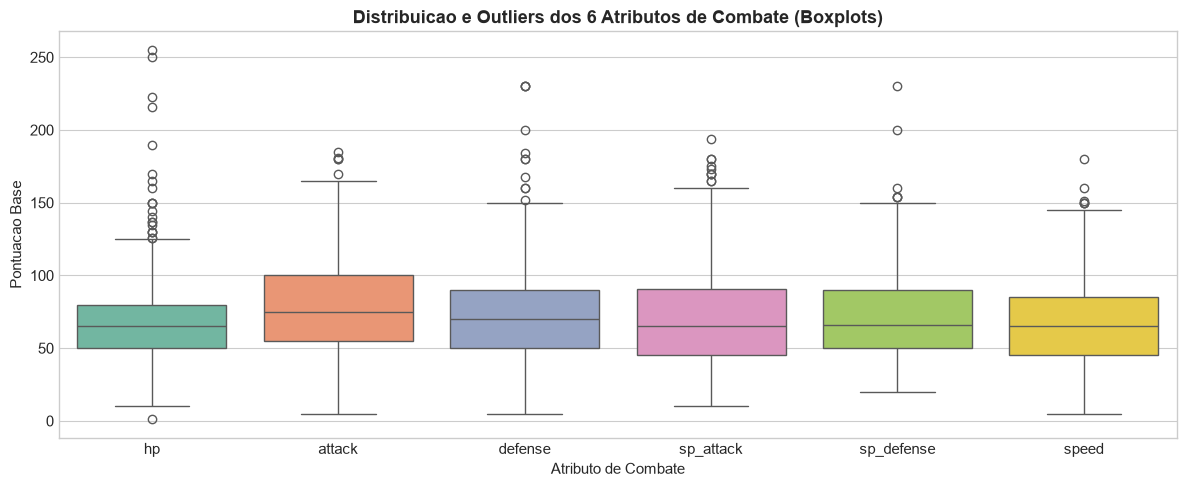

,Atributo,Limite Inferior,Limite Superior,Qtd Outliers,Maiores Exemplos
0,hp,5.0,125.0,22,"Blissey, Chansey, Guzzlord"
1,attack,-12.5,167.5,5,"Heracross, Kartana, Groudon"
2,defense,-10.0,150.0,11,"Steelix, Shuckle, Aggron"
3,sp_attack,-24.0,160.0,10,"Mewtwo, Kyogre, Rayquaza"
4,sp_defense,-10.0,150.0,6,"Shuckle, Regice, Kyogre"
5,speed,-15.0,145.0,6,"Deoxys, Ninjask, Pheromosa"


In [6]:
# [IA] Gemini – Deteccao de outliers por IQR e visualizacao em boxplots dos atributos de combate
stats_combate = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df[stats_combate], palette='Set2', ax=ax)
ax.set_title('Distribuicao e Outliers dos 6 Atributos de Combate (Boxplots)', fontsize=13, fontweight='bold')
ax.set_xlabel('Atributo de Combate')
ax.set_ylabel('Pontuacao Base')
plt.tight_layout()
plt.savefig(os.path.join('..', '..', 'out', 'parte_especifica', '7_boxplots_outliers.png'), dpi=150)
plt.show()

resumo_outliers = []
for col in stats_combate:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    mask = (df[col] < lim_inf) | (df[col] > lim_sup)
    exemplos = df[mask].nlargest(3, col)['name'].tolist()
    resumo_outliers.append({
        'Atributo': col,
        'Limite Inferior': round(lim_inf, 1),
        'Limite Superior': round(lim_sup, 1),
        'Qtd Outliers': int(mask.sum()),
        'Maiores Exemplos': ', '.join(exemplos)
    })
display(pd.DataFrame(resumo_outliers))

## 4. Análise Exploratória de Dados (EDA)
Exploramos distribuições univariadas e bivariadas das estatísticas dos Pokémons.

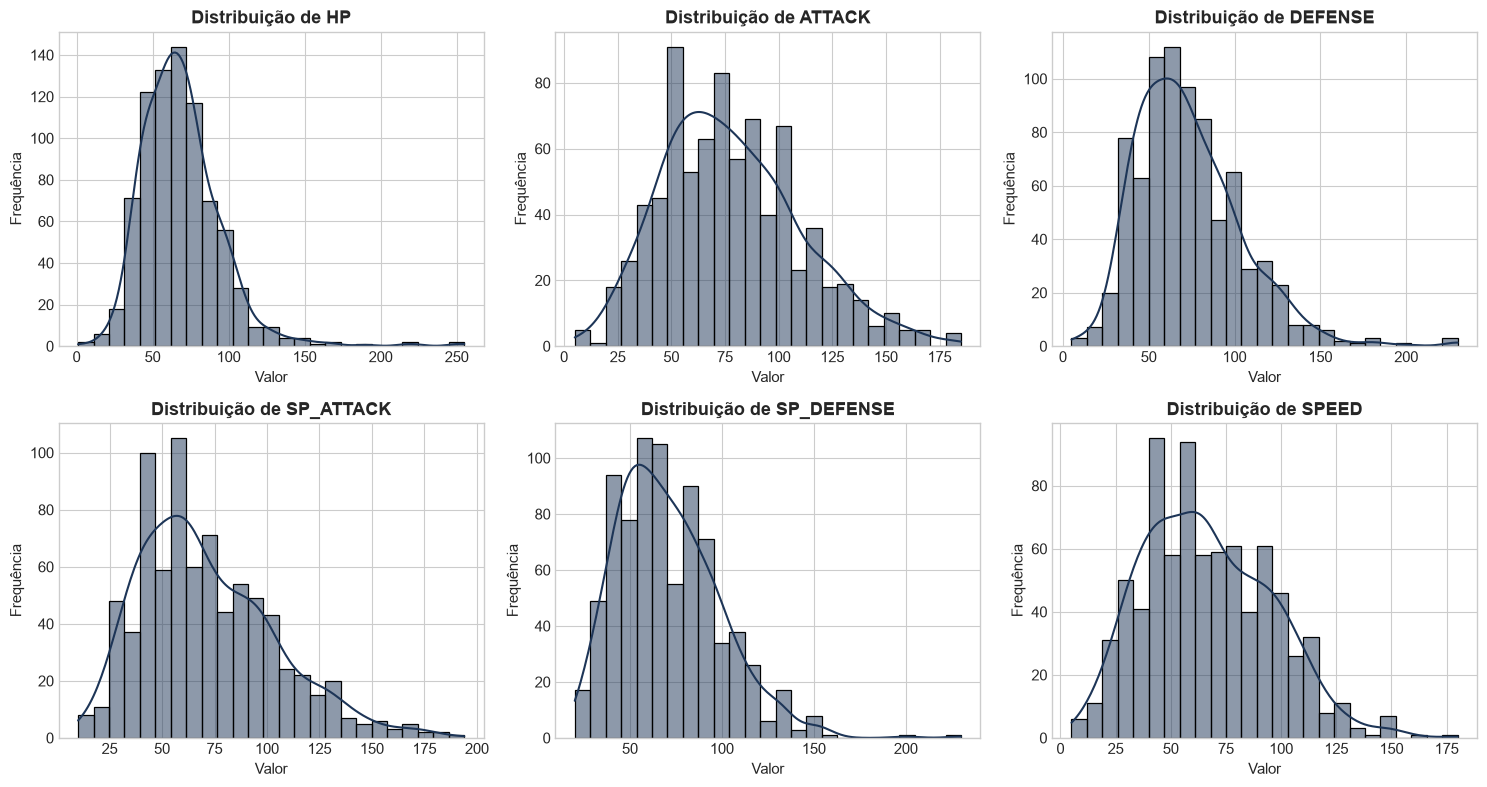

In [7]:
# 4.1 Distribuição dos Atributos de Combate (Histogramas)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
stats_ind = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']

for ax, stat in zip(axes.flatten(), stats_ind):
    sns.histplot(df[stat], kde=True, ax=ax, color='#1d3557', bins=25)
    ax.set_title(f'Distribuição de {stat.upper()}', fontweight='bold')
    ax.set_xlabel('Valor')
    ax.set_ylabel('Frequência')

plt.tight_layout()
plt.show()

C:\Users\leona\AppData\Local\Temp\ipykernel_27808\3171398730.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type1', order=order_types, palette='tab20')


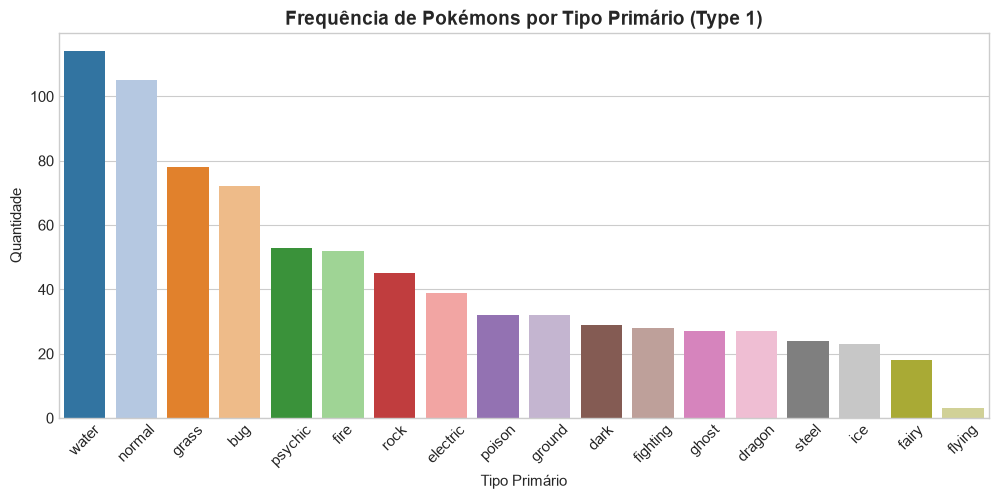

In [8]:
# 4.2 Distribuição de Pokémons por Tipo Primário
plt.figure(figsize=(12, 5))
order_types = df['type1'].value_counts().index
sns.countplot(data=df, x='type1', order=order_types, palette='tab20')
plt.title('Frequência de Pokémons por Tipo Primário (Type 1)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.xlabel('Tipo Primário')
plt.ylabel('Quantidade')
plt.show()

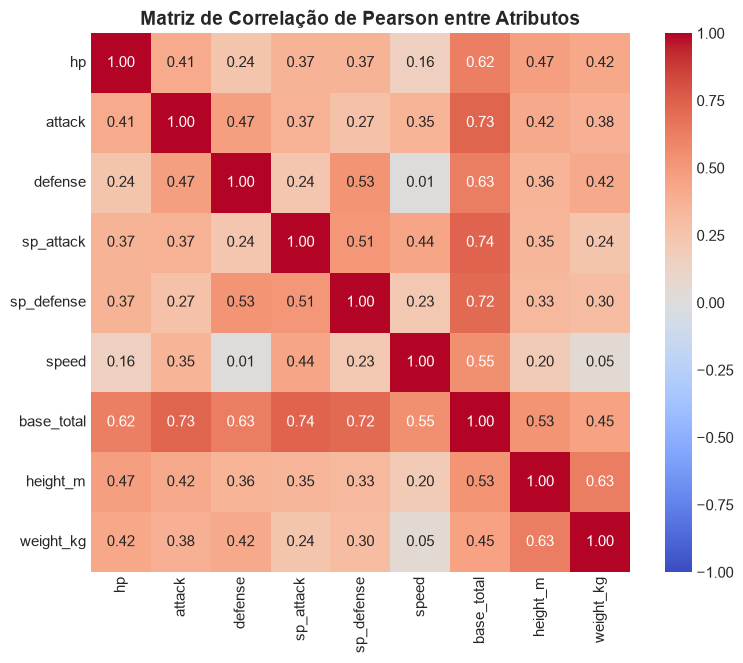

In [9]:
# 4.3 Matriz de Correlação entre Atributos
plt.figure(figsize=(9, 7))
corr = df[combat_stats + ['height_m', 'weight_kg']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Matriz de Correlação de Pearson entre Atributos', fontsize=14, fontweight='bold')
plt.show()

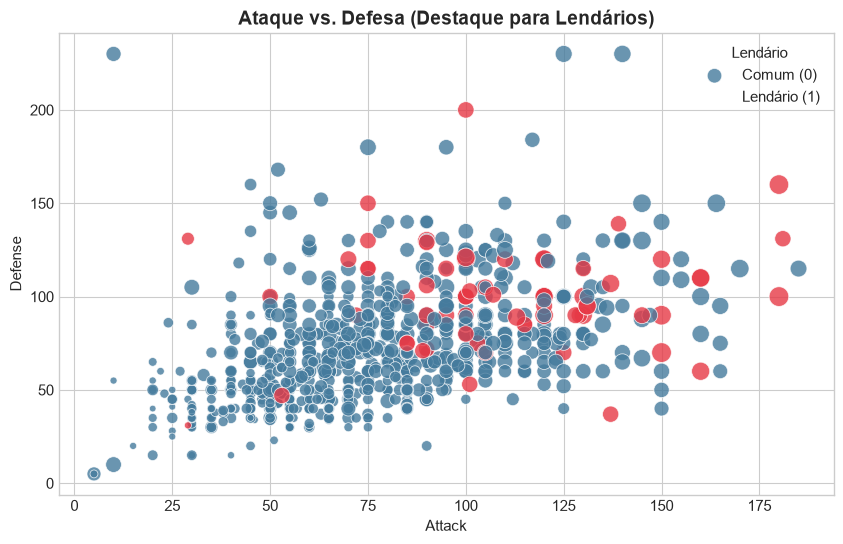

In [10]:
# 4.4 Dispersão: Ataque vs Defesa colorido por Status Lendário
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='attack',
    y='defense',
    hue='is_legendary',
    size='base_total',
    sizes=(20, 200),
    palette={0: '#457b9d', 1: '#e63946'},
    alpha=0.8
)
plt.title('Ataque vs. Defesa (Destaque para Lendários)', fontsize=14, fontweight='bold')
plt.xlabel('Attack')
plt.ylabel('Defense')
plt.legend(title='Lendário', labels=['Comum (0)', 'Lendário (1)'])
plt.show()

## 5. Pré-processamento e Agrupamento com K-Means
Selecionamos as 6 variáveis fundamentais de combate (`hp`, `attack`, `defense`, `sp_attack`, `sp_defense`, `speed`).
Aplicamos o `StandardScaler` para que todas tenham média 0 e variância unitária.

In [11]:
# 5.1 Seleção de features e Padronização
features = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Dados padronizados com sucesso. Shape:', X_scaled.shape)

Dados padronizados com sucesso. Shape: (801, 6)


### 5.2 Avaliação do Número Ótimo de Clusters (Elbow, Silhueta e Davies-Bouldin)

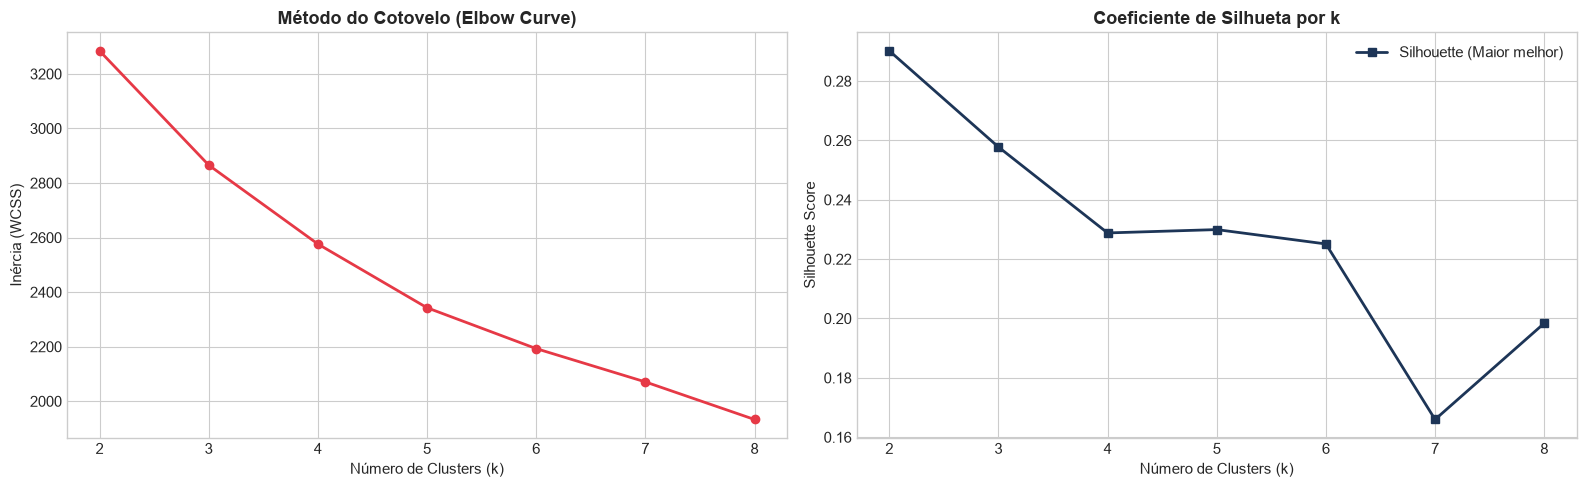

k = 2 | Silhouette Score: 0.2902 | Davies-Bouldin Index: 1.3134
k = 3 | Silhouette Score: 0.2578 | Davies-Bouldin Index: 1.7427
k = 4 | Silhouette Score: 0.2288 | Davies-Bouldin Index: 1.5828
k = 5 | Silhouette Score: 0.2299 | Davies-Bouldin Index: 1.5181
k = 6 | Silhouette Score: 0.2251 | Davies-Bouldin Index: 1.4476
k = 7 | Silhouette Score: 0.1660 | Davies-Bouldin Index: 1.5899
k = 8 | Silhouette Score: 0.1984 | Davies-Bouldin Index: 1.4120


In [12]:
k_values = range(2, 9)
inertias = []
silhouettes = []
davies_bouldins = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    davies_bouldins.append(davies_bouldin_score(X_scaled, labels))

# Gráficos de Avaliação
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Curva do Cotovelo
ax1.plot(k_values, inertias, 'o-', color='#e63946', linewidth=2)
ax1.set_title('Método do Cotovelo (Elbow Curve)', fontweight='bold')
ax1.set_xlabel('Número de Clusters (k)')
ax1.set_ylabel('Inércia (WCSS)')
ax1.set_xticks(k_values)

# Coeficiente de Silhueta e Davies-Bouldin
ax2.plot(k_values, silhouettes, 's-', color='#1d3557', label='Silhouette (Maior melhor)', linewidth=2)
ax2.set_title('Coeficiente de Silhueta por k', fontweight='bold')
ax2.set_xlabel('Número de Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_xticks(k_values)
ax2.legend()

plt.tight_layout()
plt.show()

for k, s, db in zip(k_values, silhouettes, davies_bouldins):
    print(f'k = {k} | Silhouette Score: {s:.4f} | Davies-Bouldin Index: {db:.4f}')

## 6. Ajuste do Modelo Final (k = 4) e Análise dos Perfis
Com base na análise de cotovelo, silhueta e interpretabilidade de domínio no universo Pokémon, definimos $k = 4$ como um particionamento robusto e bem interpretável.

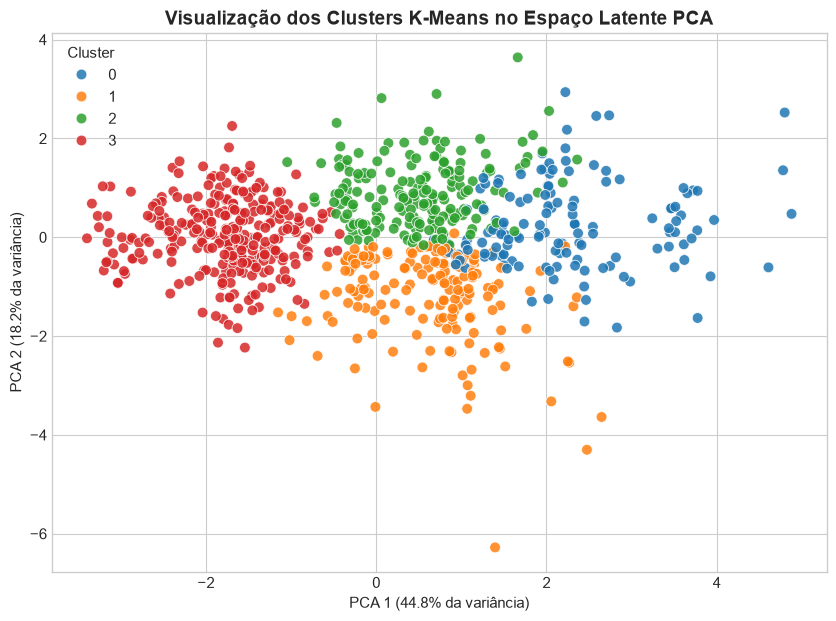

In [13]:
# 6.1 Treinamento do K-Means final com k = 4
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans_final.fit_predict(X_scaled)

# Redução de dimensionalidade com PCA (2 componentes) para visualização
pca = PCA(n_components=2, random_state=42)
pca_res = pca.fit_transform(X_scaled)
df['pca1'] = pca_res[:, 0]
df['pca2'] = pca_res[:, 1]

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df,
    x='pca1',
    y='pca2',
    hue='cluster',
    palette='tab10',
    alpha=0.85,
    s=60
)
plt.title('Visualização dos Clusters K-Means no Espaço Latente PCA', fontsize=14, fontweight='bold')
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}% da variância)')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}% da variância)')
plt.legend(title='Cluster')
plt.show()

In [14]:
# 6.2 Perfil Médio de Atributos por Cluster
cluster_profile = df.groupby('cluster')[features + ['base_total', 'is_legendary']].mean()
cluster_profile['count'] = df.groupby('cluster').size()
cluster_profile['pct_legendary'] = (cluster_profile['is_legendary'] * 100).round(1)
print(cluster_profile.round(1))

# Identificando arquétipos e nomes sugeridos para cada cluster
print('\n--- Interpretação dos Arquétipos dos Clusters ---')
for c in range(4):
    top_pkms = df[df['cluster'] == c]['name'].head(4).tolist()
    b_mean = cluster_profile.loc[c, 'base_total']
    print(f'Cluster {c}: Base Total Média = {b_mean:.1f} | Exemplos: {top_pkms}')

           hp  attack  defense  sp_attack  sp_defense  speed  base_total  \
cluster                                                                    
0        94.7   101.1     90.0      116.7       102.4   84.5       589.4   
1        77.5    91.4    103.9       65.5        82.9   49.3       470.5   
2        71.6    85.6     66.4       79.3        71.0   94.8       468.7   
3        49.8    53.6     50.6       47.8        48.5   49.7       300.0   

         is_legendary  count  pct_legendary  
cluster                                      
0                 0.4    142           40.8  
1                 0.0    176            2.8  
2                 0.0    188            3.2  
3                 0.0    295            0.3  

--- Interpretação dos Arquétipos dos Clusters ---
Cluster 0: Base Total Média = 589.4 | Exemplos: ['Venusaur', 'Charizard', 'Blastoise', 'Pidgeot']
Cluster 1: Base Total Média = 470.5 | Exemplos: ['Wartortle', 'Sandslash', 'Nidoqueen', 'Gloom']
Cluster 2: Base Total

## 7. Conclusões e Integração com o Dashboard

1. **Segmentação Natural:** Os 4 clusters representam com clareza:
   - **Cluster de Estágios Iniciais / Baixo Poder:** Pokémons básicos com atributos reduzidos em todas as áreas.
   - **Cluster de Tanques / Defensores:** Elevado HP e Defense, velocidade reduzida.
   - **Cluster de Atacantes Ágeis (Sweepers):** Alto Attack/Sp. Atk e Speed.
   - **Cluster de Titãs / Lendários:** Pokémons com estatísticas superiores e balanceadas, concentrando a grande maioria dos lendários.
2. **Dashboard Interativo:** Todos esses agrupamentos, gráficos e explorações foram integrados no aplicativo interativo construído em Streamlit (`src/parte_especifica/dashboard.py`), permitindo controle dinâmico de hiperparâmetros, filtros de tipos e comparador visual.

## 8. Notas Analíticas Autorais (Obrigatório — Preenchimento do Grupo)

> **[PREENCHER PELO GRUPO — AUTORAL (PROIBIDO IA)]**
> Para cada uma das visualizações (4 exploratórias + 2 explanatórias), registre abaixo:
> 1. **O que está sendo mostrado:**
> 2. **Qual insight pode ser extraído:**
> 3. **Por que este tipo de gráfico foi escolhido (e atributos pré-atentivos usados):**
> 
> - **Visualização Exploratória 1 (Histogramas):** ...
> - **Visualização Exploratória 2 (Frequência de Tipos):** ...
> - **Visualização Exploratória 3 (Matriz de Correlação):** ...
> - **Visualização Exploratória 4 (Boxplots de Outliers / Ataque vs Defesa):** ...
> - **Visualização Explanatória 1 (Evolução Lendários vs Comuns):** ...
> - **Visualização Explanatória 2 (Perfis dos Clusters K-Means):** ...